In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from textblob import TextBlob
from wordcloud import WordCloud
from collections import Counter

print("All libraries imported successfully!")

All libraries imported successfully!


In [39]:
df = pd.read_csv("chatgpt_reviews.csv")
df.head()

,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [40]:
df = pd.read_csv("/content/chatgpt_reviews.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (196727, 4)


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [41]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Display column names
print(df.columns)

Index(['review_id', 'review', 'ratings', 'review_date'], dtype='object')


In [42]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   review_id    196727 non-null  object
 1   review       196721 non-null  object
 2   ratings      196727 non-null  int64 
 3   review_date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB

Missing Values:
review_id      0
review         6
ratings        0
review_date    0
dtype: int64

Duplicate Rows:
2511


In [25]:

# Calculate sentiment scores
def get_sentiment_scores(text):
    analysis = TextBlob(str(text))
    return (
        analysis.sentiment.polarity,
        analysis.sentiment.subjectivity
    )

# Apply sentiment analysis to non-empty reviews
valid_reviews = df["review"].str.strip().ne("")

scores = df.loc[valid_reviews, "review"].apply(
    get_sentiment_scores
)

df["polarity"] = np.nan
df["subjectivity"] = np.nan

df.loc[valid_reviews, "polarity"] = scores.apply(
    lambda x: x[0]
)

df.loc[valid_reviews, "subjectivity"] = scores.apply(
    lambda x: x[1]
)

# Display results
display(
    df[["review", "polarity", "subjectivity"]].head(10)
)


,review,polarity,subjectivity
0,good,0.7000,0.600000
1,good,0.7000,0.600000
2,nice app,0.6000,1.000000
3,"nice, ig",0.6000,1.000000
4,"this is a great app, the bot is so accurate to...",0.4125,0.542949
5,so nice app,0.6000,1.000000
6,"just love this app, or guy",0.5000,0.600000
7,great app,0.8000,0.750000
8,Very impressive,1.0000,1.000000
9,helps with coding a lot this ai is great for e...,0.8000,0.750000


In [26]:

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Fill missing reviews with empty strings
df["review"] = df["review"].fillna("")

# Convert review date to datetime
df["review_date"] = pd.to_datetime(
    df["review_date"], errors="coerce"
)

# Ensure ratings are numeric
df["ratings"] = pd.to_numeric(
    df["ratings"], errors="coerce"
)

# Verify cleaning results
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (194216, 6)

Missing Values:
review_id       0
review          0
ratings         0
review_date     0
polarity        0
subjectivity    0
dtype: int64

Data Types:
review_id               object
review                  object
ratings                  int64
review_date     datetime64[ns]
polarity               float64
subjectivity           float64
dtype: object


In [27]:

# Categorize sentiment using polarity
df["sentiment"] = np.select(
    [
        df["polarity"] > 0,
        df["polarity"] < 0,
        df["polarity"] == 0
    ],
    [
        "Positive",
        "Negative",
        "Neutral"
    ],
    default="No Review"
)

# Count reviews in each category
print(df["sentiment"].value_counts())

# Calculate percentages
print(
    df["sentiment"].value_counts(normalize=True) * 100
)


sentiment
Positive    148219
Neutral      37928
Negative      8069
Name: count, dtype: int64
sentiment
Positive    76.316575
Neutral     19.528772
Negative     4.154653
Name: proportion, dtype: float64


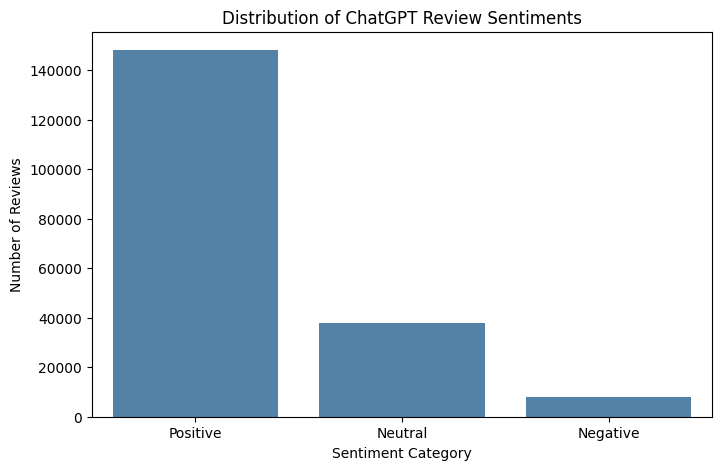

In [28]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"],
    color="steelblue"
)

plt.title("Distribution of ChatGPT Review Sentiments")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")

plt.show()


ratings
1     11966
2      3346
3      8046
4     22603
5    148255
Name: count, dtype: int64


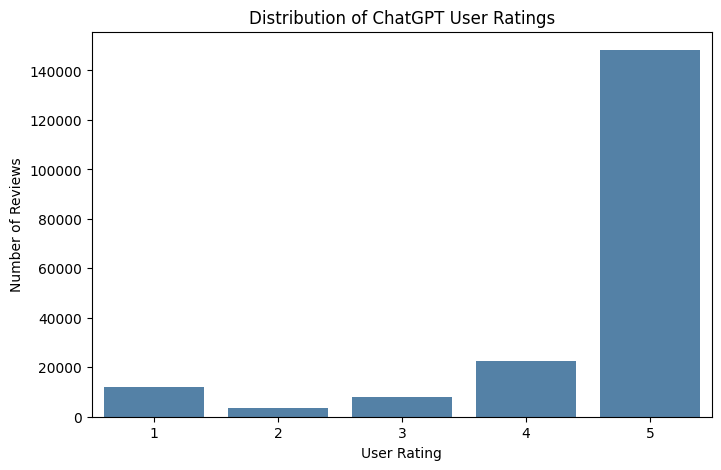

In [29]:

# Count ratings
print(df["ratings"].value_counts().sort_index())

# Visualize rating distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="ratings",
    color="steelblue"
)

plt.title("Distribution of ChatGPT User Ratings")
plt.xlabel("User Rating")
plt.ylabel("Number of Reviews")

plt.show()


sentiment,Negative,Neutral,Positive
ratings,,,
1,3563,4641,3762
2,707,971,1668
3,822,1911,5313
4,870,3956,17777
5,2107,26449,119699


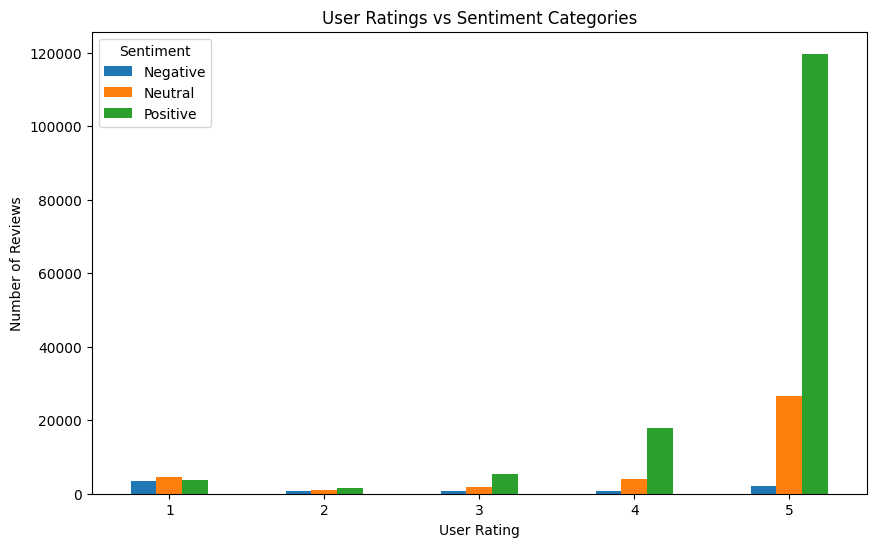

In [30]:

# Create rating vs sentiment table
rating_sentiment = pd.crosstab(
    df["ratings"],
    df["sentiment"]
)

display(rating_sentiment)

# Visualize comparison
rating_sentiment.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("User Ratings vs Sentiment Categories")
plt.xlabel("User Rating")
plt.ylabel("Number of Reviews")
plt.legend(title="Sentiment")
plt.xticks(rotation=0)

plt.show()


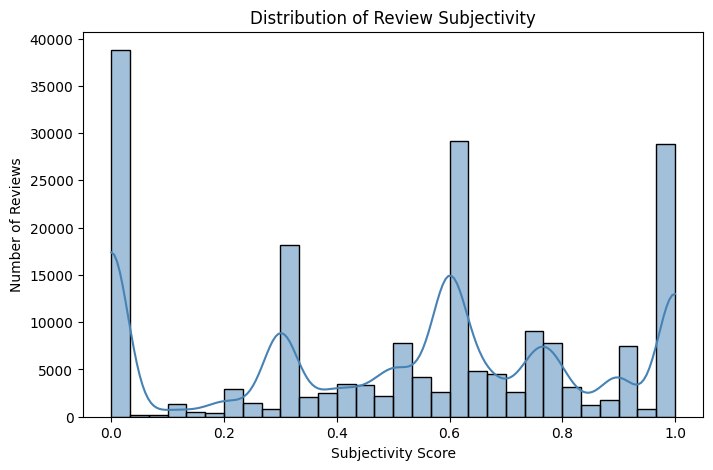

Average Subjectivity: 0.517


In [31]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="subjectivity",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Review Subjectivity")
plt.xlabel("Subjectivity Score")
plt.ylabel("Number of Reviews")

plt.show()

print(
    "Average Subjectivity:",
    round(df["subjectivity"].mean(), 3)
)


In [32]:

# Filter positive reviews with high ratings
positive_reviews = df[
    (df["sentiment"] == "Positive") &
    (df["ratings"] >= 4)
].copy()

print("Total Positive Reviews:", len(positive_reviews))

display(
    positive_reviews[["review", "ratings", "sentiment"]].head()
)


Total Positive Reviews: 137476


,review,ratings,sentiment
0,good,5,Positive
1,good,5,Positive
2,nice app,5,Positive
3,"nice, ig",5,Positive
4,"this is a great app, the bot is so accurate to...",5,Positive


In [33]:

import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Combine positive review text
positive_text = " ".join(
    positive_reviews["review"].astype(str)
).lower()

# Extract words
words = re.findall(r"\b[a-z]{3,}\b", positive_text)

# Remove stopwords
stop_words = set(ENGLISH_STOP_WORDS) | {
    "chatgpt", "gpt", "chat", "app", "openai"
}

filtered_words = [
    word for word in words
    if word not in stop_words
]

# Count word frequencies
word_counts = Counter(filtered_words)

print("Top 15 Positive Keywords:")
print(word_counts.most_common(15))


Top 15 Positive Keywords:
[('good', 35008), ('best', 17556), ('nice', 12695), ('great', 11118), ('helpful', 9263), ('amazing', 8308), ('love', 8268), ('useful', 7158), ('really', 6574), ('like', 6128), ('excellent', 5948), ('use', 5382), ('awesome', 4901), ('just', 4268), ('help', 3194)]


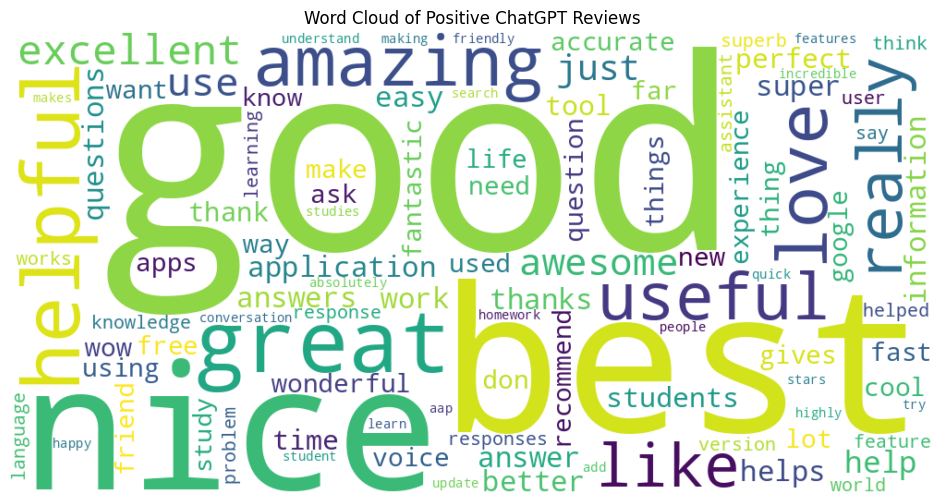

In [34]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100,
    colormap="viridis"
).generate_from_frequencies(word_counts)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive ChatGPT Reviews")
plt.show()


In [35]:

# Filter negative reviews
negative_reviews = df[
    (df["sentiment"] == "Negative") &
    (df["review"].str.strip() != "")
].copy()

print("Total Negative Reviews:", len(negative_reviews))

# Display sample negative reviews
display(
    negative_reviews[
        ["review", "ratings", "polarity"]
    ].head(10)
)


Total Negative Reviews: 8069


,review,ratings,polarity
10,I am not very happy with this because chatgpt ...,3,-0.172527
119,not good,1,-0.350000
134,Too expensive,1,-0.500000
176,"Correct answer Accuracy 10 %,always provide wr...",1,-0.500000
222,"I get a ""something went wrong"" error so I can'...",1,-0.500000
229,"there are typing bug. if I backspace, previous...",4,-0.166667
262,So so bad not working on camera,1,-0.700000
303,This is not nice app I hate it 😡,1,-0.550000
313,chat gpt is helpful sometimes but there's some...,1,-0.450000
378,I failed my math homework :/,1,-0.375000


,Keyword,Frequency
0,wrong,857
1,bad,852
2,like,654
3,use,641
4,just,622
5,time,615
6,answer,567
7,don,466
8,information,436
9,answers,409


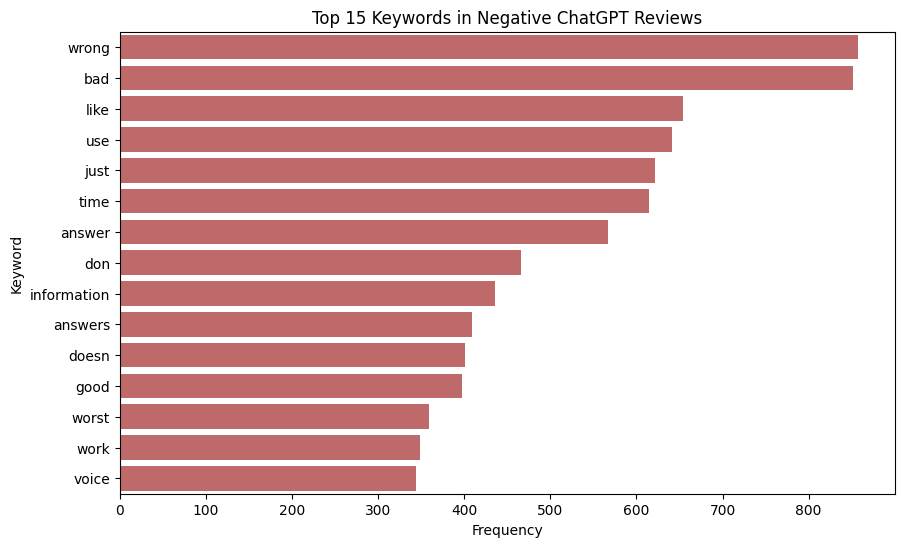

In [36]:

# Combine negative reviews
negative_text = " ".join(
    negative_reviews["review"].astype(str)
).lower()

# Extract words
negative_words = re.findall(
    r"\b[a-z]{3,}\b",
    negative_text
)

# Remove stopwords
negative_filtered = [
    word for word in negative_words
    if word not in stop_words
]

# Count keywords
negative_word_counts = Counter(negative_filtered)

# Display top 15
negative_top_words = negative_word_counts.most_common(15)

negative_keyword_df = pd.DataFrame(
    negative_top_words,
    columns=["Keyword", "Frequency"]
)

display(negative_keyword_df)

# Visualize
plt.figure(figsize=(10, 6))

sns.barplot(
    data=negative_keyword_df,
    x="Frequency",
    y="Keyword",
    color="indianred"
)

plt.title("Top 15 Keywords in Negative ChatGPT Reviews")
plt.xlabel("Frequency")
plt.ylabel("Keyword")
plt.show()


In [37]:

print("CHATGPT REVIEW ANALYSIS - FINAL SUMMARY")
print("-" * 45)

print("Total Cleaned Reviews:", len(df))

print("\nSentiment Distribution (%):")
print(
    (df["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nAverage Polarity:",
      round(df["polarity"].mean(), 3))

print("Average Subjectivity:",
      round(df["subjectivity"].mean(), 3))

print("\nTop 10 Positive Keywords:")
print(word_counts.most_common(10))

print("\nTop 10 Negative Keywords:")
print(negative_word_counts.most_common(10))


CHATGPT REVIEW ANALYSIS - FINAL SUMMARY
---------------------------------------------
Total Cleaned Reviews: 194216

Sentiment Distribution (%):
sentiment
Positive    76.32
Neutral     19.53
Negative     4.15
Name: proportion, dtype: float64

Average Polarity: 0.447
Average Subjectivity: 0.517

Top 10 Positive Keywords:
[('good', 35008), ('best', 17556), ('nice', 12695), ('great', 11118), ('helpful', 9263), ('amazing', 8308), ('love', 8268), ('useful', 7158), ('really', 6574), ('like', 6128)]

Top 10 Negative Keywords:
[('wrong', 857), ('bad', 852), ('like', 654), ('use', 641), ('just', 622), ('time', 615), ('answer', 567), ('don', 466), ('information', 436), ('answers', 409)]
